# Eksploracyjna analiza czynników ryzyka chorób układu krążenia
> **Przedmiot:** Analiza danych w Pythonie  

> **Zespół:** Julia Mielnik, Zuzanna Miechowicz, Wiktoria Dobosz, Marta Kaczmarkiewicz

> **Źródło danych:** Cardiovascular Disease Dataset (Kaggle)

---

 


# 1. Wprowadzenie 

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno

# Wczytanie danych 
df = pd.read_csv("cardio_train.csv", sep=";")
df.head()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           70000 non-null  int64  
 1   age          70000 non-null  int64  
 2   gender       70000 non-null  int64  
 3   height       70000 non-null  int64  
 4   weight       70000 non-null  float64
 5   ap_hi        70000 non-null  int64  
 6   ap_lo        70000 non-null  int64  
 7   cholesterol  70000 non-null  int64  
 8   gluc         70000 non-null  int64  
 9   smoke        70000 non-null  int64  
 10  alco         70000 non-null  int64  
 11  active       70000 non-null  int64  
 12  cardio       70000 non-null  int64  
dtypes: float64(1), int64(12)
memory usage: 6.9 MB


## 2. Porządkowanie i czyszczenie danych

### 2.1. Wstępna diagnostyka, indeksowanie i transformacja podstawowych zmiennych
W pierwszym kroku sprawdzamy formalne braki danych, ustawiamy kolumnę `id` jako indeks (aby zachować identyfikatory pacjentów, ale wykluczyć je ze statystyk i wykrywania duplikatów), usuwamy dokładne duplikaty oraz przeliczamy wiek z dni na lata.

Liczba braków w kolumnach:
age            0
gender         0
height         0
weight         0
ap_hi          0
ap_lo          0
cholesterol    0
gluc           0
smoke          0
alco           0
active         0
cardio         0
dtype: int64


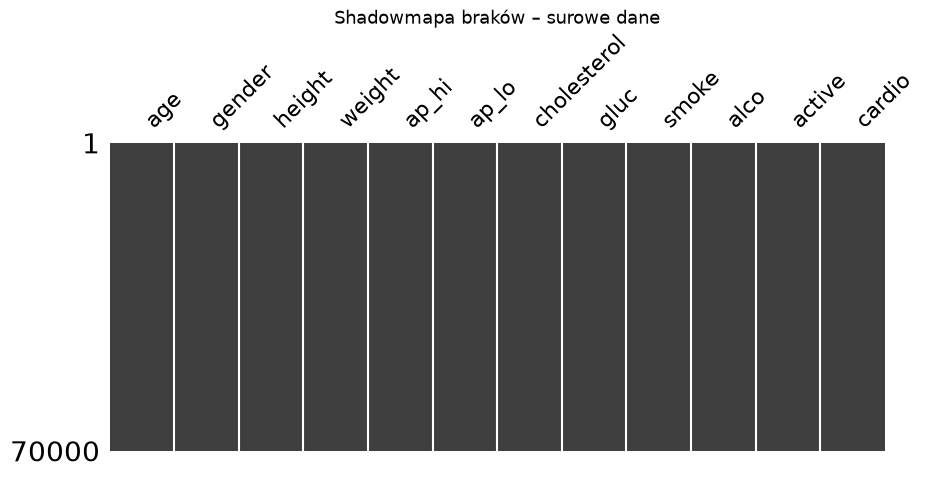

Liczba zduplikowanych rekordów pacjentów: 24


,count,min,mean,50%,max
gender,69976.0,1.0,1.349648,1.0,2.0
height,69976.0,55.0,164.359152,165.0,250.0
weight,69976.0,10.0,74.208519,72.0,200.0
ap_hi,69976.0,-150.0,128.820453,120.0,16020.0
ap_lo,69976.0,-70.0,96.636261,80.0,11000.0
cholesterol,69976.0,1.0,1.366997,1.0,3.0
gluc,69976.0,1.0,1.226535,1.0,3.0
smoke,69976.0,0.0,0.088159,0.0,1.0
alco,69976.0,0.0,0.053790,0.0,1.0
active,69976.0,0.0,0.803718,1.0,1.0


In [3]:
# Ustawienie 'id' jako indeksu 
if 'id' in df.columns:
    df = df.set_index('id')

# Sprawdzenie formalnych braków danych przed czyszczeniem
print("Liczba braków w kolumnach:")
print(df.isnull().sum())

# Shadowmapa surowego zbioru 
msno.matrix(df, figsize=(10, 4), sparkline=False)
plt.title("Shadowmapa braków – surowe dane", fontsize=13)
plt.show()

# Sprawdzenie i usunięcie duplikatów 
duplikaty = df.duplicated().sum()
print(f"Liczba zduplikowanych rekordów pacjentów: {duplikaty}")
df = df.drop_duplicates()

# Przeliczenie wieku z dni na lata
if 'age' in df.columns:
    df['age_years'] = (df['age'] / 365.25).round(1)
    df = df.drop(columns=['age'])

# Podgląd zakresów wartości (min/max) 
display(df.describe().T[['count', 'min', 'mean', '50%', 'max']])

### 2.2. Reguły walidacji danych i wizualizacja naruszeń
Analiza statystyk `min` i `max` pokazuje, że choć w zbiorze nie ma pustych komórek, występują w nim ewidentne błędy pomiarowe i błędy wprowadzania (np. ujemne lub wielotysięczne ciśnienie krwi, niefizjologiczny wzrost i waga).

Przyjmujemy następujące reguły poprawności fizjologicznej:
* **Ciśnienie skurczowe (`ap_hi`):** 60 – 240 mmHg
* **Ciśnienie rozkurczowe (`ap_lo`):** 40 – 160 mmHg
* **Relacja ciśnień:** `ap_hi > ap_lo` (skurczowe musi być wyższe niż rozkurczowe)
* **Wzrost (`height`):** 120 – 220 cm
* **Waga (`weight`):** 35 – 200 kg

,Liczba naruszeń,Udział (%)
ap_lo >= ap_hi (odwrócone/równe),1236,1.77
ap_lo poza zakresem (40–160),1025,1.46
ap_hi poza zakresem (60–240),228,0.33
height poza zakresem (120–220),53,0.08
weight poza zakresem (35–200),20,0.03


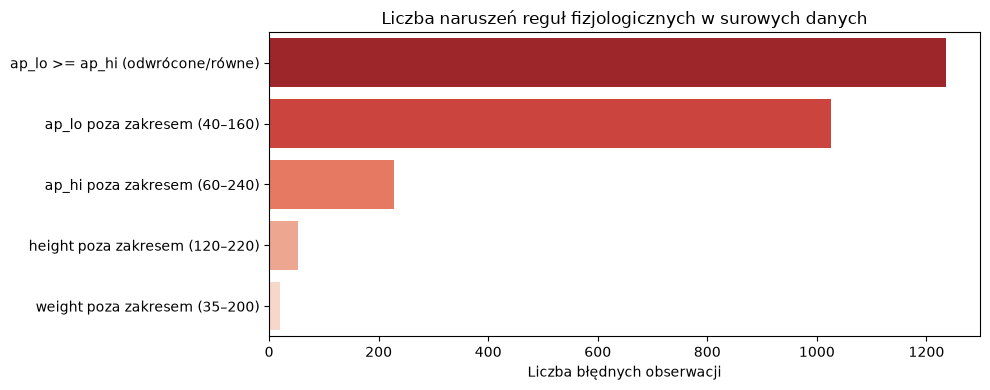

In [5]:
# Zdefiniowanie naruszeń 
naruszenia = {
    'ap_hi poza zakresem (60–240)': (df['ap_hi'] < 60) | (df['ap_hi'] > 240),
    'ap_lo poza zakresem (40–160)': (df['ap_lo'] < 40) | (df['ap_lo'] > 160),
    'ap_lo >= ap_hi (odwrócone/równe)': df['ap_lo'] >= df['ap_hi'],
    'height poza zakresem (120–220)': (df['height'] < 120) | (df['height'] > 220),
    'weight poza zakresem (35–200)': (df['weight'] < 35) | (df['weight'] > 200)
}

# Tabela podsumowująca liczbę i udział procentowy błędów
podsumowanie_bledow = pd.DataFrame({
    'Liczba naruszeń': {k: v.sum() for k, v in naruszenia.items()},
    'Udział (%)': {k: round(v.mean() * 100, 2) for k, v in naruszenia.items()}
}).sort_values('Liczba naruszeń', ascending=False)

display(podsumowanie_bledow)

# Wizualizacja naruszeń
plt.figure(figsize=(10, 4))
sns.barplot(
    x=podsumowanie_bledow['Liczba naruszeń'],
    y=podsumowanie_bledow.index,
    hue=podsumowanie_bledow.index,
    palette="Reds_r",
    legend=False
)
plt.title("Liczba naruszeń reguł fizjologicznych w surowych danych")
plt.xlabel("Liczba błędnych obserwacji")
plt.ylabel("")
plt.tight_layout()
plt.show()